# Olist marketplace analysis
DSC8307 · Advent 2026

Run from top to bottom using Python 3.14. Install `requirements.txt`. Download the [Olist CSV files](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) into this folder or set `OLIST_DATA_DIR` to their location. The notebook also looks one directory up for the supplied archive layout.

In [1]:
import os
from collections import Counter
from itertools import combinations
from pathlib import Path

os.environ.setdefault('OMP_NUM_THREADS', '4')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor, IsolationForest
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.impute import SimpleImputer
from sklearn.metrics import (adjusted_rand_score, average_precision_score, brier_score_loss,
    mean_absolute_error, root_mean_squared_error, precision_recall_curve, roc_auc_score,
    silhouette_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
data_dir = Path(os.environ.get('OLIST_DATA_DIR', '.'))
if 'OLIST_DATA_DIR' not in os.environ and not (data_dir / 'olist_orders_dataset.csv').exists():
    data_dir = Path('..')
files = dict(
    (key, f'olist_{key}_dataset.csv') for key in
    ['orders','order_items','customers','products','sellers','order_payments','order_reviews','geolocation']
)
files['translation'] = 'product_category_name_translation.csv'
tables = {key: pd.read_csv(data_dir / name, dtype={
    col: str for col in ['customer_zip_code_prefix','seller_zip_code_prefix','geolocation_zip_code_prefix']
}) for key,name in files.items()}
def audit(frame):
    return pd.Series({'rows': len(frame), 'columns': frame.shape[1],
        'duplicate_rows': frame.duplicated().sum(),
        'missing_by_column': {col: int(count) for col, count in frame.isna().sum().items() if count}})
audit_table = pd.DataFrame({name: audit(frame) for name, frame in tables.items()}).T
display(audit_table.drop(columns='missing_by_column'))
for name, missing in audit_table.missing_by_column.items():
    if missing:
        print(name, missing)

Matplotlib is building the font cache; this may take a moment.


,rows,columns,duplicate_rows
orders,99441,8,0
order_items,112650,7,0
customers,99441,5,0
products,32951,9,0
sellers,3095,4,0
order_payments,103886,5,0
order_reviews,99224,7,0
geolocation,1000163,5,261831
translation,71,2,0


orders {'order_approved_at': 160, 'order_delivered_carrier_date': 1783, 'order_delivered_customer_date': 2965}
products {'product_category_name': 610, 'product_name_lenght': 610, 'product_description_lenght': 610, 'product_photos_qty': 610, 'product_weight_g': 2, 'product_length_cm': 2, 'product_height_cm': 2, 'product_width_cm': 2}
order_reviews {'review_comment_title': 87656, 'review_comment_message': 58247}


## 1. Preparation and exploratory analysis

Orders, products, customers and sellers are dimension or header tables. Items have an order-and-line key, payments can have multiple entries per order, and reviews may repeat. Joining raw items to raw payments or reviews would inflate revenue and the sample size. ZIP prefixes have multiple coordinate observations. Use customer and seller state for route comparisons and leave raw geolocation out of joins. Use merchandise value (BRL) exclusive of freight, and describe payments and reviews in the audit without assuming either is necessary for a task.

Orphan rows: {'items/order': 0, 'items/product': 0, 'items/seller': 0, 'orders/customer': 0}
Purchase range: 2016-09-04 21:15:19 2018-10-17 17:30:18
Valid labeled deliveries: 96470 late: 0.06773090079817559
Delivered status with missing/invalid timing: 8


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

,days,promise_days
count,96470.000000,96470.000000
mean,12.558217,24.372738
std,9.546156,8.758428
min,0.533414,3.000000
25%,6.766204,19.000000
50%,10.217477,24.000000
75%,15.720182,29.000000
max,209.628611,156.000000


Item rows without category: 1603
Negative merchandise or freight rows: 0


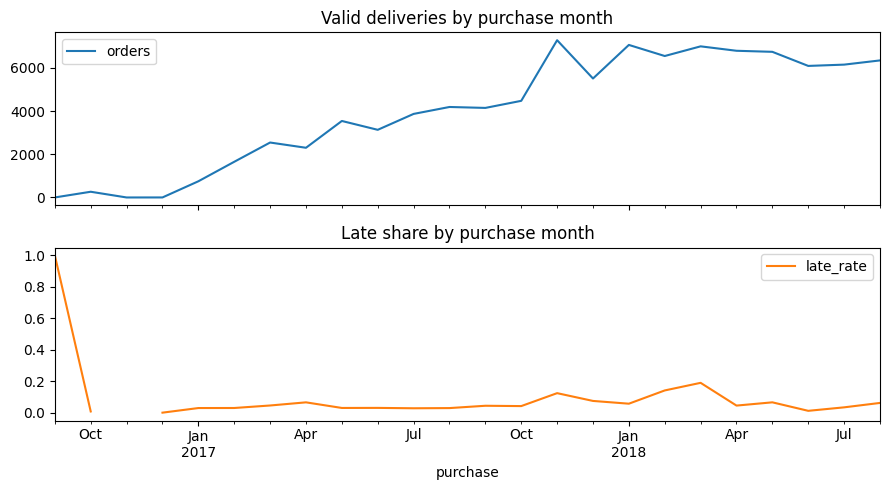

In [2]:
orders = tables['orders'].copy()
items = tables['order_items'].copy()
customers, products, sellers, translation = (tables[key] for key in ['customers','products','sellers','translation'])
for frame, key in [(orders,'order_id'), (customers,'customer_id'), (products,'product_id'),
                   (sellers,'seller_id'), (translation,'product_category_name'),
                   (items,['order_id','order_item_id'])]:
    assert not frame.duplicated(key).any()
print('Orphan rows:', {key: int((~frame[col].isin(parent[col])).sum()) for key,frame,col,parent in [
    ('items/order',items,'order_id',orders), ('items/product',items,'product_id',products),
    ('items/seller',items,'seller_id',sellers), ('orders/customer',orders,'customer_id',customers)]})
for col in orders.filter(regex='date|timestamp|approved'):
    orders[col] = pd.to_datetime(orders[col], errors='raise')
items['shipping_limit_date'] = pd.to_datetime(items['shipping_limit_date'])
orders['purchase'] = orders.order_purchase_timestamp
orders['delivered'] = orders.order_delivered_customer_date
orders['days'] = (orders.delivered - orders.purchase).dt.total_seconds() / 86400
orders['promise_days'] = (orders.order_estimated_delivery_date.dt.normalize() -
                          orders.purchase.dt.normalize()).dt.days
orders['late'] = (orders.delivered.dt.normalize() > orders.order_estimated_delivery_date.dt.normalize()).astype(int)
valid = (orders.order_status.eq('delivered') & orders.days.ge(0) &
         orders.promise_days.ge(0) & orders.order_estimated_delivery_date.notna())
delivered = orders.loc[valid].copy()
print('Purchase range:', orders.purchase.min(), orders.purchase.max())
print('Valid labeled deliveries:', len(delivered), 'late:', delivered.late.mean())
print('Delivered status with missing/invalid timing:', int((orders.order_status.eq('delivered') & ~valid).sum()))
display(orders.order_status.value_counts(), delivered[['days','promise_days']].describe())
product_meta = products.merge(translation, on='product_category_name', how='left', validate='many_to_one')
product_meta['category'] = product_meta.product_category_name_english.fillna(product_meta.product_category_name)
lines = items.merge(product_meta[['product_id','category','product_weight_g']], on='product_id',
                    how='left', validate='many_to_one')
lines = lines.merge(sellers[['seller_id','seller_state']], on='seller_id', how='left', validate='many_to_one')
print('Item rows without category:', lines.category.isna().sum())
print('Negative merchandise or freight rows:', (lines[['price','freight_value']] < 0).any(axis=1).sum())
monthly = delivered.set_index('purchase').resample('MS').agg(orders=('late','size'), late_rate=('late','mean'))
monthly.plot(subplots=True, figsize=(9,5), title=['Valid deliveries by purchase month','Late share by purchase month'])
plt.tight_layout()
plt.show()

## 2. Market baskets

A basket is one delivered order with at least one known category. Count a category once per basket. Enumerate all two-category combinations directly, following the association-rule definitions of Agrawal and Srikant. Support is pair count divided by baskets, confidence is pair count divided by antecedent count, and lift compares confidence with the consequent's overall frequency. Rank recent candidates by historical pair volume and inspect their recurrence in later data. Report the highest-volume pairs even if none meet the original 20-order screen. A five-order screen provides exploratory leads and a sensitivity comparison.

In [3]:
basket_lines = lines.loc[lines.order_id.isin(delivered.order_id)].dropna(subset=['category'])
baskets = basket_lines.groupby('order_id').category.agg(lambda s: sorted(set(s)))
basket_dates = delivered.set_index('order_id').purchase.reindex(baskets.index)
def rule_counts(group):
    singles = Counter(category for basket in group for category in basket)
    pairs = Counter(pair for basket in group for pair in combinations(basket, 2))
    return singles, pairs

basket_cutoff = pd.Timestamp('2018-05-01')
early = baskets[basket_dates < basket_cutoff]
later = baskets[basket_dates >= basket_cutoff]
single, pairs = rule_counts(early)
later_single, later_pairs = rule_counts(later)
rows = []
for (a,b), count in pairs.items():
    for antecedent, consequent in [(a,b),(b,a)]:
        recent = later_pairs[(a,b)]
        expected = later_single[a] * later_single[b] / len(later)
        rows.append((antecedent,consequent,count,count/len(early),count/single[antecedent],
                     count*len(early)/(single[a]*single[b]),recent,recent/len(later),
                     recent/expected if expected else np.nan))
rules = pd.DataFrame(rows, columns=['antecedent','consequent','pair_count','support','confidence',
                                    'lift','later_count','later_support','later_lift'])
print('Baskets:', len(baskets), 'multi-category share:', baskets.map(len).gt(1).mean(),
      'early / later:', len(early), len(later))
print('Qualifying unordered pairs by minimum discovery count (lift > 1.5):',
      {minimum: len(rules.query('pair_count >= @minimum and lift > 1.5'))//2 for minimum in [3,5,10,20]})
top_rules = rules.query('antecedent < consequent').nlargest(8,'pair_count')
display(top_rules.round(5))
display(rules.query('pair_count >= 5 and lift > 1.5').sort_values(
    ['pair_count','confidence'], ascending=False).head(10).round(5))

Baskets: 95138 multi-category share: 0.007599487060901007 early / later: 69905 25233
Qualifying unordered pairs by minimum discovery count (lift > 1.5): {3: 0, 5: 0, 10: 0, 20: 0}


,antecedent,consequent,pair_count,support,confidence,lift,later_count,later_support,later_lift
30,bed_bath_table,furniture_decor,58,0.00083,0.00834,0.12014,12,0.00048,0.08983
110,bed_bath_table,home_confort,38,0.00054,0.00546,1.19322,5,0.00020,0.75693
122,furniture_decor,housewares,18,0.00026,0.00371,0.06869,6,0.00024,0.05286
14,baby,cool_stuff,17,0.00024,0.00859,0.19611,3,0.00012,0.18351
2,baby,toys,15,0.00021,0.00758,0.16993,4,0.00016,0.17753
72,baby,bed_bath_table,11,0.00016,0.00556,0.05585,6,0.00024,0.07879
6,bed_bath_table,housewares,10,0.00014,0.00144,0.02661,10,0.00040,0.05541
138,furniture_decor,garden_tools,10,0.00014,0.00206,0.05145,6,0.00024,0.16071


,antecedent,consequent,pair_count,support,confidence,lift,later_count,later_support,later_lift


## 3. Seller segmentation

Use delivered order lines to measure observed throughput and GMV. For service, use single-seller deliveries so one customer's combined order outcome is attributed only where a single seller participated. Carrier and geography still contribute to the measured outcome. Require ten such orders to reduce unstable rates and keep lower-volume sellers in a separate onboarding cohort. Standardize features after log-transforming skewed volume and value. Compare candidate partitions by silhouette and initialization stability (adjusted Rand index).

,k,silhouette,repeat_ARI,smallest_segment
0,2,0.253,0.963,348
1,3,0.227,0.995,253
2,4,0.221,0.977,155
3,5,0.227,0.979,62
4,6,0.212,0.970,65


Seller master: 3095 observed delivered: 2970 eligible: 1217 below service minimum or no delivered sales: 1878


,sellers,orders,gmv,value_per_order,late_rate,median_days
segment,,,,,,
0,869,36.0,3859.80,97.240,0.041,8.972
1,348,21.5,4301.55,161.085,0.117,13.015


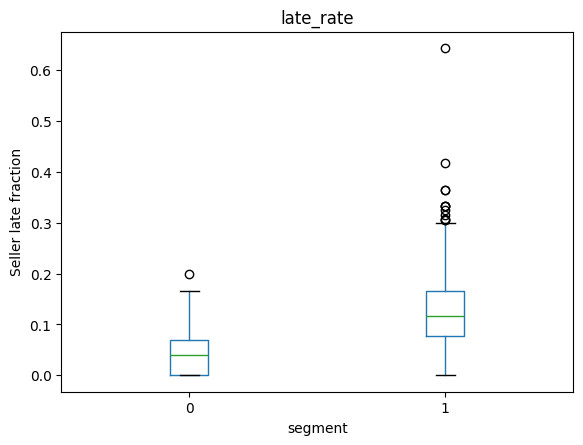

In [4]:
del_lines = lines[lines.order_id.isin(delivered.order_id)]
seller_orders = del_lines.groupby(['seller_id','order_id'], as_index=False).agg(value=('price','sum'))
single_seller = seller_orders.groupby('order_id').size().eq(1)
service = seller_orders[seller_orders.order_id.isin(single_seller[single_seller].index)].merge(
    delivered[['order_id','days','late']], on='order_id', validate='one_to_one')
profiles = seller_orders.groupby('seller_id').agg(orders=('order_id','size'), gmv=('value','sum'))
profiles['value_per_order'] = profiles.gmv / profiles.orders
profiles = profiles.join(service.groupby('seller_id').agg(service_orders=('late','size'),
                        late_rate=('late','mean'), median_days=('days','median')))
eligible = profiles.loc[profiles.service_orders.ge(10)].copy()
features = ['orders','value_per_order','late_rate','median_days']
seller_values = eligible[features].copy()
seller_values[['orders','value_per_order']] = np.log1p(seller_values[['orders','value_per_order']])
z = StandardScaler().fit_transform(seller_values)
scores, partitions = [], {}
for k in range(2,7):
    labels = KMeans(n_clusters=k,n_init=20,random_state=SEED).fit_predict(z)
    repeat = KMeans(n_clusters=k,n_init=20,random_state=4).fit_predict(z)
    partitions[k] = labels
    scores.append((k,silhouette_score(z,labels),adjusted_rand_score(labels,repeat),
                   np.bincount(labels).min()))
quality = pd.DataFrame(scores,columns=['k','silhouette','repeat_ARI','smallest_segment'])
display(quality.round(3))
# Keep segments large enough for distinct service programs.
chosen_k = int(quality.query('smallest_segment >= 20').sort_values('silhouette').iloc[-1].k)
eligible['segment'] = partitions[chosen_k]
summary = eligible.groupby('segment')[['orders','gmv','value_per_order','late_rate','median_days']].median()
summary.insert(0,'sellers',eligible.segment.value_counts())
print('Seller master:', len(sellers), 'observed delivered:', len(profiles), 'eligible:', len(eligible),
      'below service minimum or no delivered sales:', len(sellers)-len(eligible))
display(summary.round(3))
eligible.boxplot(column='late_rate',by='segment',grid=False)
plt.suptitle('')
plt.ylabel('Seller late fraction')
plt.show()

## 4. Unusual orders for operational review

Rank completed orders retrospectively for exception triage. Isolation Forest combines volume, price, freight and realized service deviations without labeled anomalies. Compare it with absolute empirical tail ranks as a transparent baseline. The review budget defines the threshold. Inspect actual values and leading reasons before taking action.

In [5]:
order_items = lines.groupby('order_id').agg(
    item_count=('order_item_id','size'), seller_count=('seller_id','nunique'),
    merchandise=('price','sum'), freight=('freight_value','sum'),
    item_weight=('product_weight_g','sum'), known_weights=('product_weight_g','count'),
    distinct_categories=('category','nunique'))
order_items.loc[order_items.known_weights.ne(order_items.item_count),'item_weight'] = np.nan
cross = lines.merge(orders[['order_id','customer_id']], on='order_id', validate='many_to_one')
cross = cross.merge(customers[['customer_id','customer_state']], on='customer_id', validate='many_to_one')
cross['cross_state'] = cross.seller_state.ne(cross.customer_state).astype(float)
order_items['cross_state'] = cross.groupby('order_id').cross_state.mean()
analysis = delivered.merge(order_items,on='order_id',validate='one_to_one')
print('Valid deliveries without order lines:', len(delivered)-len(analysis))
review = analysis.set_index('order_id').copy()
review['delay_days'] = (review.delivered.dt.normalize() - review.order_estimated_delivery_date.dt.normalize()).dt.days
review['freight_share'] = review.freight.div((review.freight+review.merchandise).replace(0,np.nan))
anomaly_cols = ['item_count','seller_count','merchandise','freight','freight_share','days','delay_days']
anomaly_input = review[anomaly_cols].fillna(review[anomaly_cols].median())
detector = IsolationForest(n_estimators=160,max_samples=1024,random_state=SEED,n_jobs=4)
review['score'] = -detector.fit(anomaly_input).score_samples(anomaly_input)
ranks = anomaly_input.rank(pct=True)
tail = (ranks - .5).abs()
review['reason'] = tail.idxmax(axis=1)
review['tail_score'] = tail.max(axis=1)
for fraction in [.005,.01,.02]:
    budget = int(len(review)*fraction)
    forest = review.nlargest(budget,'score')
    baseline = review.nlargest(budget,'tail_score')
    print(f'Budget {budget}: overlap {len(forest.index.intersection(baseline.index)) / budget:.1%}, '
          f'late share {forest.late.mean():.1%}, median delivery {forest.days.median():.1f} days')
display(review.nlargest(8,'score')[anomaly_cols+['reason','score']].reset_index(drop=True).round(3))

Valid deliveries without order lines: 0


Budget 482: overlap 44.8%, late share 28.4%, median delivery 15.6 days
Budget 964: overlap 45.3%, late share 26.7%, median delivery 15.2 days
Budget 1929: overlap 45.6%, late share 24.7%, median delivery 13.6 days


,item_count,seller_count,merchandise,freight,freight_share,days,delay_days,reason,score
0,10,2,1519.46,347.24,0.186,11.496,-24,item_count,0.777
1,8,1,13440.00,224.08,0.016,18.123,-6,merchandise,0.775
2,7,2,859.66,456.47,0.347,22.344,-16,freight,0.773
3,11,1,1361.89,626.64,0.315,39.018,-10,freight,0.768
4,6,1,2919.40,323.44,0.100,13.206,-34,freight,0.765
5,10,1,2849.90,168.70,0.056,14.115,-19,item_count,0.760
6,1,1,2029.00,63.86,0.031,126.008,96,days,0.757
7,11,2,773.50,274.79,0.262,11.287,-14,item_count,0.755


## 5. Purchase-time delivery prediction

Late means delivery after the end of the promised calendar date. Duration is elapsed time in days. Predict for eventually delivered orders with valid outcomes and item records. Features reflect basket, geography, purchase timing and the promised date, assuming Olist supplies that date at checkout. Exclude approval, carrier handoff, shipping deadlines, reviews and other outcome information. Earlier orders must have been delivered before model fit or threshold selection. Validate on February–April 2018 purchases and test on May–August 2018 purchases to focus on the sustained ordering period. Validation outcomes available by May 1 are used for the operating threshold. Inspect month-level label coverage and errors to gauge sensitivity to cohort timing. The extract leaves non-delivered or unobserved orders outside the estimand.

In [6]:
analysis['purchase_hour'] = analysis.purchase.dt.hour
analysis['purchase_weekday'] = analysis.purchase.dt.dayofweek
analysis['purchase_month'] = analysis.purchase.dt.month
feature_cols = ['item_count','seller_count','merchandise','freight','item_weight','distinct_categories',
                'cross_state','purchase_hour','purchase_weekday','purchase_month','promise_days']
val_start, test_start, test_end = pd.to_datetime(['2018-02-01','2018-05-01','2018-09-01'])
train = analysis[(analysis.purchase < val_start) & (analysis.delivered < val_start)]
val_purchased = analysis[analysis.purchase.between(val_start,test_start,inclusive='left')]
val = val_purchased[val_purchased.delivered < test_start]
test = analysis[analysis.purchase.between(test_start,test_end,inclusive='left')].copy()
print('Train, validation, test:', [(len(part), round(part.late.mean(),4)) for part in [train,val,test]])
print('Validation purchases with outcomes still unavailable at test start:', len(val_purchased)-len(val))
all_holdout = orders[orders.purchase.between(test_start,test_end,inclusive='left')]
coverage = all_holdout.assign(labeled=all_holdout.order_id.isin(test.order_id)).groupby(
    all_holdout.purchase.dt.strftime('%Y-%m')).labeled.agg(['size','sum','mean'])
display(coverage.round(4))
X_train, X_val, X_test = (part[feature_cols] for part in [train,val,test])
classification = {
    'Prevalence': (np.full(len(val),train.late.mean()),np.full(len(test),train.late.mean())),
    'Logistic': None,
    'Boosted': None,
    'Boosted without promise': None,
}
for name, model in [
    ('Logistic', make_pipeline(SimpleImputer(add_indicator=True),StandardScaler(),LogisticRegression(max_iter=500))),
    ('Boosted', HistGradientBoostingClassifier(max_iter=150,max_leaf_nodes=23,random_state=SEED)),
    ('Boosted without promise', HistGradientBoostingClassifier(max_iter=150,max_leaf_nodes=23,random_state=SEED))
]:
    cols = feature_cols[:-1] if name.endswith('without promise') else feature_cols
    model.fit(X_train[cols],train.late)
    classification[name] = (model.predict_proba(X_val[cols])[:,1],model.predict_proba(X_test[cols])[:,1])
class_rows = []
for name,(pv,pt) in classification.items():
    class_rows.append((name,average_precision_score(val.late,pv),average_precision_score(test.late,pt),
                       roc_auc_score(test.late,pt),brier_score_loss(test.late,pt)))
class_metrics = pd.DataFrame(class_rows,columns=['model','validation_AP','test_AP','test_ROC_AUC','test_Brier'])
display(class_metrics.round(4))
class_model = class_metrics.sort_values('validation_AP').iloc[-1].model
pv,pt = classification[class_model]
precision,recall,thresholds = precision_recall_curve(val.late,pv)
f1 = 2*precision*recall/np.maximum(precision+recall,1e-12)
threshold = thresholds[np.argmax(f1[:-1])]
predicted_late = pt >= threshold
tp = int((predicted_late & test.late.eq(1)).sum())
fp = int((predicted_late & test.late.eq(0)).sum())
fn = int((~predicted_late & test.late.eq(1)).sum())
tn = len(test)-tp-fp-fn
print(class_model, 'threshold', round(threshold,4), 'TP FP FN TN', tp,fp,fn,tn,
      'precision', round(tp/max(tp+fp,1),4), 'recall', round(tp/(tp+fn),4))

Train, validation, test: [(47794, np.float64(0.0499)), (17563, np.float64(0.1193)), (25352, np.float64(0.044))]
Validation purchases with outcomes still unavailable at test start: 2793


,size,sum,mean
purchase,,,
2018-05,6873,6749,0.9820
2018-06,6167,6096,0.9885
2018-07,6292,6156,0.9784
2018-08,6512,6351,0.9753


,model,validation_AP,test_AP,test_ROC_AUC,test_Brier
0,Prevalence,0.1193,0.0440,0.5000,0.0421
1,Logistic,0.1764,0.0606,0.6256,0.0420
2,Boosted,0.1219,0.0770,0.6564,0.0417
3,Boosted without promise,0.1192,0.0453,0.5162,0.0424


Logistic threshold 0.0238 TP FP FN TN 1061 20355 54 3882 precision 0.0495 recall 0.9516


,model,validation_MAE,test_MAE,test_RMSE,test_bias
0,Training median,7.245,5.108,6.770,1.537
1,Checkout promise,11.528,13.225,15.835,12.620
2,Ridge,6.137,4.609,6.339,1.886
3,Boosted MAE,6.436,4.045,5.994,0.432
4,Boosted MAE without promise,6.354,4.433,6.207,1.174


,orders,late_rate,MAE,AP
purchase_month_label,,,,
2018-05,6749,0.066,4.916,0.126
2018-06,6096,0.012,5.484,0.030
2018-07,6156,0.034,4.438,0.046
2018-08,6351,0.062,3.610,0.068


,orders,late_rate,MAE,AP
cross_state,,,,
False,10217,0.051,2.960,0.141
True,15135,0.039,5.723,0.053


,predicted,observed,orders
late_probability,,,
"(-0.0009123, 0.0221]",0.017,0.010,3169
"(0.0221, 0.0283]",0.025,0.029,3169
"(0.0283, 0.0343]",0.031,0.022,3169
"(0.0343, 0.0406]",0.037,0.034,3169
"(0.0406, 0.0469]",0.044,0.062,3169
"(0.0469, 0.0548]",0.051,0.081,3169
"(0.0548, 0.0702]",0.061,0.069,3169
"(0.0702, 0.999]",0.090,0.045,3169


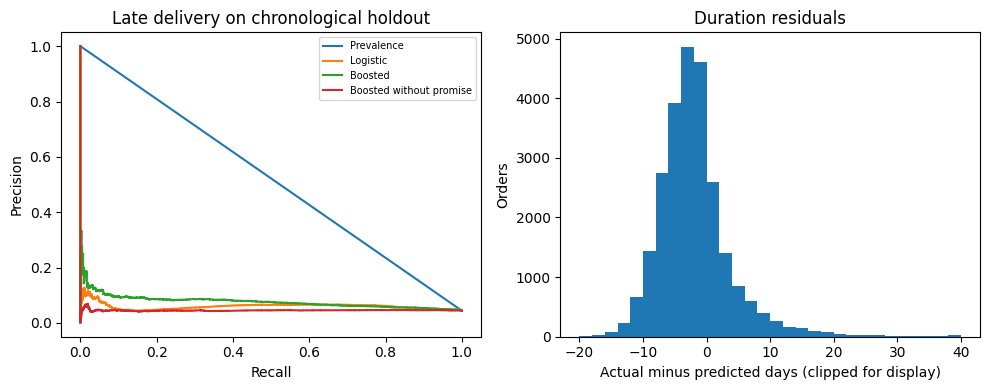

In [7]:
duration = {
    'Training median': (np.full(len(val),train.days.median()),np.full(len(test),train.days.median())),
    'Checkout promise': (X_val.promise_days.to_numpy(),X_test.promise_days.to_numpy()),
}
for name, model in [
    ('Ridge',make_pipeline(SimpleImputer(add_indicator=True),StandardScaler(),Ridge(alpha=10))),
    ('Boosted MAE',HistGradientBoostingRegressor(loss='absolute_error',max_iter=150,max_leaf_nodes=23,random_state=SEED)),
    ('Boosted MAE without promise',HistGradientBoostingRegressor(loss='absolute_error',max_iter=150,max_leaf_nodes=23,random_state=SEED))
]:
    cols = feature_cols[:-1] if name.endswith('without promise') else feature_cols
    model.fit(X_train[cols],train.days)
    duration[name] = (model.predict(X_val[cols]).clip(0),model.predict(X_test[cols]).clip(0))
reg_metrics = pd.DataFrame([
    (name,mean_absolute_error(val.days,pv),mean_absolute_error(test.days,pt),
     root_mean_squared_error(test.days,pt),np.mean(pt-test.days))
    for name,(pv,pt) in duration.items()],
    columns=['model','validation_MAE','test_MAE','test_RMSE','test_bias'])
display(reg_metrics.round(3))
reg_model = reg_metrics.sort_values('validation_MAE').iloc[0].model
test['late_probability'] = classification[class_model][1]
test['predicted_days'] = duration[reg_model][1]
test['absolute_error'] = (test.predicted_days-test.days).abs()
test['purchase_month_label'] = test.purchase.dt.strftime('%Y-%m')
for group_col in ['purchase_month_label','cross_state']:
    group_key = test[group_col] if group_col != 'cross_state' else test.cross_state.gt(0)
    grouped = test.groupby(group_key)
    display(grouped.agg(orders=('late','size'),late_rate=('late','mean'),MAE=('absolute_error','mean'))
            .assign(AP=grouped.apply(lambda g: average_precision_score(g.late,g.late_probability)
                                     if g.late.any() else np.nan, include_groups=False)).round(3))
calibration = test.groupby(pd.qcut(test.late_probability, 8, duplicates='drop'), observed=True).agg(
    predicted=('late_probability','mean'), observed=('late','mean'), orders=('late','size'))
display(calibration.round(3))
fig, axes = plt.subplots(1,2,figsize=(10,4))
for name,(_,probability) in classification.items():
    p,r,_ = precision_recall_curve(test.late,probability)
    axes[0].plot(r,p,label=name)
axes[0].set(xlabel='Recall',ylabel='Precision',title='Late delivery on chronological holdout')
axes[0].legend(fontsize=7)
residual = test.days-test.predicted_days
axes[1].hist(residual.clip(-20,40),bins=30)
axes[1].set(xlabel='Actual minus predicted days (clipped for display)',ylabel='Orders',title='Duration residuals')
plt.tight_layout()
plt.show()

### Operational use

Test cross-category placements against a randomized control and track incremental contribution margin, returns and delivery delays. Pilot seller support by observed segment and reassess membership periodically. Keep anomaly alerts for human triage and record confirmed causes. Evaluate delivery models prospectively on complete cohorts, monitor calibration and errors by route and month, and validate a separate workflow for cancellations and unobserved orders.